# Agente Inteligente para la Predicción de Ventas Diarias — Corporación Favorita
## Notebook reconstruido para la cuarta entrega

**Autores:** Juan Camilo Acuña Rojas y Luis Miguel Hernández  
**Afiliación:** Facultad de Ingeniería, Universidad de Ibagué  
**Asignatura:** Sistemas Inteligentes  
**Docente:** Dra. Alexandra La Cruz

Este cuaderno reconstruye el flujo de trabajo descrito en la tercera entrega y añade los experimentos pendientes: optimización de LightGBM con Optuna, evaluación de Tweedie, comparación con una red neuronal compacta inspirada en N-BEATS, evaluación temporal, SHAP y pronóstico de `test.csv`.

> **Importante:** los resultados de la tercera entrega (LightGBM RMSLE 0,419; ETS 0,487; promedio móvil 0,522; naïve semanal 0,617) se conservan como antecedentes. Este notebook vuelve a calcular los resultados desde los datos. No se deben presentar como resultados nuevos hasta ejecutar todas las celdas.

## 0. Cómo ejecutar el notebook

1. En Google Colab, selecciona **Entorno de ejecución → Cambiar tipo de entorno de ejecución** y activa GPU si está disponible (la red neuronal también funciona en CPU, pero tardará más).
2. Ejecuta las celdas en orden.
3. Cuando se solicite, carga el ZIP oficial de Kaggle que contiene `train.csv`, `test.csv`, `stores.csv`, `oil.csv`, `holidays_events.csv` y `transactions.csv`, o configura la carpeta de Google Drive.
4. Guarda los resultados en la carpeta de salida. Se recomienda mantener el dataset original en Drive y no subirlo a GitHub.

El notebook no contiene datos inventados ni necesita rutas del computador del desarrollador.

In [8]:
import zipfile
import os

zip_path = '/content/store-sales-time-series-forecasting (3).zip'
extract_path = '/content/favorita_project/data'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Archivos descomprimidos correctamente:")
print(os.listdir(extract_path))

Archivos descomprimidos correctamente:
['store-sales-time-series-forecasting (2).zip']


In [7]:
import os

print("Archivos que están en /content:")
print(os.listdir("/content"))

Archivos que están en /content:
['.config', '.ipynb_checkpoints', 'favorita_project', 'store-sales-time-series-forecasting (3).zip', 'sample_data']


In [4]:
import os

rutas = [
    "/content/store-sales-time-series-forecasting (2).zip",
    "/content/favorita_project/data",
    "/content/favorita_project/data/train.csv"
]

for ruta in rutas:
    print(ruta, "➡️", os.path.exists(ruta))

/content/store-sales-time-series-forecasting (2).zip ➡️ False
/content/favorita_project/data ➡️ True
/content/favorita_project/data/train.csv ➡️ False


In [12]:
import zipfile
import os

zip_interno = '/content/favorita_project/data/store-sales-time-series-forecasting (2).zip'
destino = '/content/favorita_project/data'

with zipfile.ZipFile(zip_interno, 'r') as zip_ref:
    zip_ref.extractall(destino)

print("Contenido encontrado:")
print(os.listdir(destino))

Contenido encontrado:
['store-sales-time-series-forecasting.zip', 'store-sales-time-series-forecasting (2).zip']


In [11]:
import os

carpeta = '/content/favorita_project/data'

print("Contenido de data:")
for archivo in os.listdir(carpeta):
    print(archivo)

Contenido de data:
store-sales-time-series-forecasting (2).zip


In [17]:
import pandas as pd
import os

DATA_DIR = '/content/favorita_project/data'

train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
stores = pd.read_csv(os.path.join(DATA_DIR, 'stores.csv'))

print("TRAIN:", train.shape)
print("TEST:", test.shape)
print("STORES:", stores.shape)

display(train.head())

TRAIN: (3000888, 6)
TEST: (28512, 5)
STORES: (54, 5)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [15]:
import zipfile
import os

zip_path = '/content/favorita_project/data/store-sales-time-series-forecasting (2).zip'
destino = '/content/favorita_project/data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    print("Primeros archivos dentro del ZIP:")
    print(zip_ref.namelist()[:15])
    zip_ref.extractall(destino)

print("\nExtracción terminada.")
print("Archivos encontrados:")
print(os.listdir(destino))

Primeros archivos dentro del ZIP:
['store-sales-time-series-forecasting.zip']

Extracción terminada.
Archivos encontrados:
['store-sales-time-series-forecasting.zip', 'store-sales-time-series-forecasting (2).zip']


In [16]:
import zipfile
import os

zip_interno = '/content/favorita_project/data/store-sales-time-series-forecasting.zip'
destino = '/content/favorita_project/data'

with zipfile.ZipFile(zip_interno, 'r') as zip_ref:
    print("Contenido del segundo ZIP:")
    print(zip_ref.namelist()[:15])
    zip_ref.extractall(destino)

print("\nArchivos finales:")
print(os.listdir(destino))

Contenido del segundo ZIP:
['holidays_events.csv', 'oil.csv', 'sample_submission.csv', 'stores.csv', 'test.csv', 'train.csv', 'transactions.csv']

Archivos finales:
['store-sales-time-series-forecasting.zip', 'sample_submission.csv', 'test.csv', 'transactions.csv', 'holidays_events.csv', 'stores.csv', 'train.csv', 'store-sales-time-series-forecasting (2).zip', 'oil.csv']


In [14]:
import os

DATA_DIR = '/content/favorita_project/data'

for raiz, carpetas, archivos in os.walk(DATA_DIR):
    print("\nCARPETA:", raiz)
    for archivo in archivos:
        print(" -", archivo)


CARPETA: /content/favorita_project/data
 - store-sales-time-series-forecasting.zip
 - store-sales-time-series-forecasting (2).zip


## 1. Instalación de dependencias

In [18]:
!pip -q install lightgbm optuna shap statsmodels scikit-learn pandas numpy matplotlib seaborn torch

## 2. Librerías y configuración

In [19]:
import os, gc, json, math, random, shutil, zipfile, warnings
from pathlib import Path
from datetime import timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error
from lightgbm import LGBMRegressor, early_stopping, log_evaluation
import lightgbm as lgb
import optuna
import shap

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Rutas: se puede cambiar BASE_DIR por una carpeta de Google Drive.
BASE_DIR = Path("/content/favorita_project")
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
MODEL_DIR = BASE_DIR / "models"
for folder in [DATA_DIR, OUTPUT_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Horizonte de predicción exigido por la competencia.
HORIZON = 16
TRAIN_START = pd.Timestamp("2015-06-01")
VALIDATION_START = pd.Timestamp("2017-07-15")
VALIDATION_END = pd.Timestamp("2017-07-30")
TEST_START = pd.Timestamp("2017-08-16")
TEST_END = pd.Timestamp("2017-08-31")

# Ajustes para controlar el consumo de Colab.
N_OPTUNA_TRIALS = 20
NN_MAX_WINDOWS = 60000
NN_EPOCHS = 8
print("LightGBM:", lgb.__version__)
print("Carpeta del proyecto:", BASE_DIR)

LightGBM: 4.6.0
Carpeta del proyecto: /content/favorita_project


## 3. Conectar Google Drive (opcional) y cargar el dataset

In [20]:
# OPCIÓN A: cargar manualmente el ZIP oficial de Kaggle desde el equipo.
# Ejecuta esta celda y selecciona el archivo ZIP descargado de la competencia.
from google.colab import files
uploaded = files.upload()

zip_candidates = [name for name in uploaded.keys() if name.lower().endswith(".zip")]
if zip_candidates:
    zip_path = Path("/content") / zip_candidates[0]
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_DIR)
    print("ZIP extraído en:", DATA_DIR)
else:
    print("No se cargó un ZIP. Si ya tienes los CSV en Drive, configura DATA_DIR manualmente.")

KeyboardInterrupt: 

In [ ]:
# OPCIÓN B: si el dataset está en Google Drive, descomenta y ajusta la ruta.
# from google.colab import drive
# drive.mount('/content/drive')
# DATA_DIR = Path('/content/drive/MyDrive/Proyecto_Favorita/dataset')
# OUTPUT_DIR = Path('/content/drive/MyDrive/Proyecto_Favorita/outputs')
# MODEL_DIR = Path('/content/drive/MyDrive/Proyecto_Favorita/models')
# for folder in [OUTPUT_DIR, MODEL_DIR]:
#     folder.mkdir(parents=True, exist_ok=True)

required_files = [
    "train.csv", "test.csv", "stores.csv", "oil.csv",
    "holidays_events.csv", "transactions.csv"
]
missing = [f for f in required_files if not (DATA_DIR / f).exists()]
if missing:
    # Busca CSV en subcarpetas creadas al descomprimir el ZIP.
    found = {}
    for f in required_files:
        matches = list(DATA_DIR.rglob(f))
        if matches:
            found[f] = matches[0]
    if len(found) == len(required_files):
        DATA_DIR = next(iter(found.values())).parent
        print("Se detectó el dataset en:", DATA_DIR)
    else:
        raise FileNotFoundError(
            "Faltan archivos: " + ", ".join(missing) +
            ". Carga el ZIP oficial o configura DATA_DIR con la carpeta que contiene los seis CSV."
        )

print("Archivos encontrados correctamente.")

## 4. Lectura eficiente y revisión inicial

In [21]:
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["date"])
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["date"])
stores = pd.read_csv(DATA_DIR / "stores.csv")
oil = pd.read_csv(DATA_DIR / "oil.csv", parse_dates=["date"])
holidays = pd.read_csv(DATA_DIR / "holidays_events.csv", parse_dates=["date"])
transactions = pd.read_csv(DATA_DIR / "transactions.csv", parse_dates=["date"])

# Reducir consumo de memoria.
train["sales"] = train["sales"].astype("float32")
train["onpromotion"] = train["onpromotion"].fillna(0).astype("float32")
test["onpromotion"] = test["onpromotion"].fillna(0).astype("float32")
for df in [train, test]:
    df["store_nbr"] = df["store_nbr"].astype("int16")

print("Train:", train.shape, "| Test:", test.shape)
print("Tiendas:", train["store_nbr"].nunique(), "| Familias:", train["family"].nunique())
display(train.head())
display(stores.head())

Train: (3000888, 6) | Test: (28512, 5)
Tiendas: 54 | Familias: 33


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0.0
1,1,2013-01-01,1,BABY CARE,0.0,0.0
2,2,2013-01-01,1,BEAUTY,0.0,0.0
3,3,2013-01-01,1,BEVERAGES,0.0,0.0
4,4,2013-01-01,1,BOOKS,0.0,0.0


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


## 5. Preprocesamiento y variables de calendario

Se mantiene la lógica documentada en la tercera entrega: calendario diario completo por serie, cierre del 25 de diciembre con venta cero, precio del petróleo completado únicamente con el último valor conocido (sin interpolación hacia el futuro), feriados por ámbito y datos externos rezagados.

In [22]:
# Identificadores de serie y unión de atributos de tienda.
series_cols = ["store_nbr", "family"]
train = train.merge(stores, on="store_nbr", how="left", validate="many_to_one")
test = test.merge(stores, on="store_nbr", how="left", validate="many_to_one")

# Calendario diario completo por combinación tienda-familia.
# Las fechas ausentes se completan con ventas cero y promoción cero.
date_min = train["date"].min()
date_max = max(train["date"].max(), test["date"].max())
all_dates = pd.date_range(date_min, date_max, freq="D")
series = train[series_cols].drop_duplicates()
calendar = pd.MultiIndex.from_product(
    [series["store_nbr"].unique(), series["family"].unique(), all_dates],
    names=["store_nbr", "family", "date"]
).to_frame(index=False)

# Mantener solo combinaciones existentes, evitando crear combinaciones artificiales.
valid_pairs = series.assign(_valid=1)
calendar = calendar.merge(valid_pairs, on=series_cols, how="inner").drop(columns="_valid")

train_cols = ["date", "store_nbr", "family", "sales", "onpromotion"]
panel = calendar.merge(
    train[train_cols], on=["date", "store_nbr", "family"], how="left"
)
panel["sales"] = panel["sales"].fillna(0).astype("float32")
panel["onpromotion"] = panel["onpromotion"].fillna(0).astype("float32")
panel = panel.sort_values(series_cols + ["date"]).reset_index(drop=True)

print("Panel diario:", panel.shape)
print("Series:", panel.groupby(series_cols, observed=True).ngroups)

Panel diario: (3036528, 5)
Series: 1782


In [30]:
# Petróleo: forward fill únicamente (no interpolación).
oil_daily = oil[["date", "dcoilwtico"]].drop_duplicates("date").sort_values("date")
oil_calendar = pd.DataFrame({"date": all_dates}).merge(oil_daily, on="date", how="left")
oil_calendar["dcoilwtico"] = oil_calendar["dcoilwtico"].ffill().bfill()
panel = panel.merge(oil_calendar, on="date", how="left")

# Transacciones por tienda: se unen como variable observada y luego se rezagan 16 días.
transactions = transactions.rename(columns={"transactions": "transactions_value"})
# Completar transacciones en una tabla independiente ordenada por tienda y fecha,
# evitando que el orden por familia propague valores de fechas futuras.
transactions_calendar = pd.MultiIndex.from_product(
    [stores["store_nbr"].unique(), all_dates],
    names=["store_nbr", "date"]
).to_frame(index=False)
transactions_calendar = transactions_calendar.merge(
    transactions[["date", "store_nbr", "transactions_value"]],
    on=["date", "store_nbr"], how="left"
).sort_values(["store_nbr", "date"])
transactions_calendar["transactions_value"] = (
    transactions_calendar.groupby("store_nbr")["transactions_value"].ffill().fillna(0)
).astype("float32")
panel = panel.merge(
    transactions_calendar, on=["date", "store_nbr"], how="left"
)

# Clasificar feriados y eventos de acuerdo con su tipo y ámbito.
hol = holidays.copy()
hol["transferred_flag"] = (hol["transferred"].fillna(False) == True).astype("int8")
# En los registros trasladados, la fecha de celebración se representa en la fila
# que contiene la fecha efectiva; la fecha original marcada como trasladada no se usa.
hol = hol[hol["transferred_flag"] == 0].copy()

def holiday_flag_rows(df, locale_name):
    return df[df["locale"].str.lower().eq(locale_name)].groupby("date").size().rename(
        f"holiday_{locale_name}"
    )

h_nat = holiday_flag_rows(hol, "national")
h_reg = holiday_flag_rows(hol, "regional")
h_loc = holiday_flag_rows(hol, "local")
h_cal = pd.DataFrame({"date": all_dates})
for s in [h_nat, h_reg, h_loc]:
    h_cal = h_cal.merge(s, left_on="date", right_index=True, how="left")
for c in ["holiday_national", "holiday_regional", "holiday_local"]:
    h_cal[c] = h_cal[c].fillna(0).clip(upper=1).astype("int8")

# Asociar feriados regionales/locales a provincia/ciudad de la tienda.
# Se construyen indicadores generales por fecha y se refinan por ubicación.
hol_national_dates = set(hol.loc[hol["locale"].str.lower().eq("national"), "date"])
regional = hol[hol["locale"].str.lower().eq("regional")][["date", "locale_name"]].drop_duplicates()
local = hol[hol["locale"].str.lower().eq("local")][["date", "locale_name"]].drop_duplicates()

panel = panel.merge(h_cal, on="date", how="left")
panel["holiday_regional"] = (
    panel[["date", "state"]].merge(
        regional, left_on=["date", "state"], right_on=["date", "locale_name"], how="left"
    )["locale_name"].notna().to_numpy().astype("int8")
)
panel["holiday_local"] = (
    panel[["date", "city"]].merge(
        local, left_on=["date", "city"], right_on=["date", "locale_name"], how="left"
    )["locale_name"].notna().to_numpy().astype("int8")
)
panel["holiday_national"] = panel["date"].isin(hol_national_dates).astype("int8")

# Días laborales adicionales: indicador basado en el tipo de evento.
work_days = hol[hol["type"].astype(str).str.lower().str.contains("work day", na=False)]
work_dates = set(work_days["date"])
panel["work_day_event"] = panel["date"].isin(work_dates).astype("int8")

# Calendario, quincena y periodo posterior al terremoto.
panel["dayofweek"] = panel["date"].dt.dayofweek.astype("int8")
panel["day"] = panel["date"].dt.day.astype("int8")
panel["month"] = panel["date"].dt.month.astype("int8")
panel["dayofyear"] = panel["date"].dt.dayofyear.astype("int16")
panel["payday"] = (
    panel["date"].dt.day.isin([15, 16]) |
    panel["date"].dt.is_month_end
).astype("int8")
panel["earthquake_period"] = (
    (panel["date"] >= pd.Timestamp("2016-04-16")) &
    (panel["date"] <= pd.Timestamp("2016-05-16"))
).astype("int8")

# Indicador de evento especial (sin asumir una clasificación adicional).
event_dates = set(hol.loc[hol["type"].astype(str).str.lower().str.contains("event", na=False), "date"])
panel["special_event"] = panel["date"].isin(event_dates).astype("int8")

print("Preprocesamiento básico finalizado.")

Preprocesamiento básico finalizado.


In [24]:
# Agregar estado y ciudad de cada tienda
columnas = ["store_nbr", "state", "city"]

atributos_tienda = stores[columnas].drop_duplicates("store_nbr")

if "state" not in panel.columns:
    panel = panel.merge(
        atributos_tienda[["store_nbr", "state"]],
        on="store_nbr",
        how="left",
        validate="many_to_one"
    )

if "city" not in panel.columns:
    panel = panel.merge(
        atributos_tienda[["store_nbr", "city"]],
        on="store_nbr",
        how="left",
        validate="many_to_one"
    )

print("Columnas recuperadas:")
print(panel[["store_nbr", "state", "city"]].head())

Columnas recuperadas:
   store_nbr      state   city
0          1  Pichincha  Quito
1          1  Pichincha  Quito
2          1  Pichincha  Quito
3          1  Pichincha  Quito
4          1  Pichincha  Quito


In [25]:
# Recalcular los indicadores de feriados regionales y locales

panel["holiday_regional"] = (
    panel[["date", "state"]].merge(
        regional,
        left_on=["date", "state"],
        right_on=["date", "locale_name"],
        how="left"
    )["locale_name"].notna().to_numpy().astype("int8")
)

panel["holiday_local"] = (
    panel[["date", "city"]].merge(
        local,
        left_on=["date", "city"],
        right_on=["date", "locale_name"],
        how="left"
    )["locale_name"].notna().to_numpy().astype("int8")
)

panel["holiday_national"] = (
    panel["date"].isin(hol_national_dates).astype("int8")
)

print("Indicadores de feriados recuperados:")
display(panel[[
    "date",
    "state",
    "city",
    "holiday_national",
    "holiday_regional",
    "holiday_local"
]].head(10))

Indicadores de feriados recuperados:


,date,state,city,holiday_national,holiday_regional,holiday_local
0,2013-01-01,Pichincha,Quito,1,0,0
1,2013-01-02,Pichincha,Quito,0,0,0
2,2013-01-03,Pichincha,Quito,0,0,0
3,2013-01-04,Pichincha,Quito,0,0,0
4,2013-01-05,Pichincha,Quito,1,0,0
5,2013-01-06,Pichincha,Quito,0,0,0
6,2013-01-07,Pichincha,Quito,0,0,0
7,2013-01-08,Pichincha,Quito,0,0,0
8,2013-01-09,Pichincha,Quito,0,0,0
9,2013-01-10,Pichincha,Quito,0,0,0


In [26]:
print("Tamaño actual del panel:", panel.shape)

print("\nColumnas:")
print(panel.columns.tolist())

print("\nColumnas duplicadas:")
print(panel.columns[panel.columns.duplicated()].tolist())

print("\nValores nulos en variables principales:")
display(panel[[
    "date",
    "sales",
    "onpromotion",
    "dcoilwtico",
    "transactions_value",
    "state",
    "city"
]].isna().sum())

Tamaño actual del panel: (3036528, 12)

Columnas:
['store_nbr', 'family', 'date', 'sales', 'onpromotion', 'dcoilwtico', 'transactions_value', 'holiday_national', 'holiday_regional', 'holiday_local', 'state', 'city']

Columnas duplicadas:
[]

Valores nulos en variables principales:


,0
date,0
sales,0
onpromotion,0
dcoilwtico,0
transactions_value,0
state,0
city,0


In [27]:
print("Filas originales de train:", len(train))
print("Filas actuales de panel:", len(panel))

print("\nFechas de train:")
print(train["date"].min(), "hasta", train["date"].max())

print("\nFechas de panel:")
print(panel["date"].min(), "hasta", panel["date"].max())

print("\nNúmero de fechas distintas:")
print("Train:", train["date"].nunique())
print("Panel:", panel["date"].nunique())

print("\nNúmero de combinaciones tienda-familia-fecha:")
print("Train:", train[["store_nbr", "family", "date"]].drop_duplicates().shape[0])
print("Panel:", panel[["store_nbr", "family", "date"]].drop_duplicates().shape[0])

Filas originales de train: 3000888
Filas actuales de panel: 3036528

Fechas de train:
2013-01-01 00:00:00 hasta 2017-08-15 00:00:00

Fechas de panel:
2013-01-01 00:00:00 hasta 2017-08-31 00:00:00

Número de fechas distintas:
Train: 1684
Panel: 1704

Número de combinaciones tienda-familia-fecha:
Train: 3000888
Panel: 3036528


In [28]:
# Conservar únicamente las fechas presentes en train
panel = panel[
    panel["date"].isin(train["date"].unique())
].copy()

panel = panel.sort_values(
    ["store_nbr", "family", "date"]
).reset_index(drop=True)

print("Filas después del ajuste:", len(panel))
print("Fecha inicial:", panel["date"].min())
print("Fecha final:", panel["date"].max())
print("Fechas distintas:", panel["date"].nunique())

Filas después del ajuste: 3000888
Fecha inicial: 2013-01-01 00:00:00
Fecha final: 2017-08-15 00:00:00
Fechas distintas: 1684


In [31]:
duplicados = panel.duplicated(
    subset=["store_nbr", "family", "date"]
).sum()

print("Combinaciones duplicadas:", duplicados)

print("\nDistribución de ventas:")
display(panel["sales"].describe())

print("\nCantidad de tiendas:", panel["store_nbr"].nunique())
print("Cantidad de familias:", panel["family"].nunique())

Combinaciones duplicadas: 0

Distribución de ventas:


,sales
count,3.000888e+06
mean,3.577757e+02
std,1.096202e+03
min,0.000000e+00
25%,0.000000e+00
50%,1.100000e+01
75%,1.958473e+02
max,1.247170e+05



Cantidad de tiendas: 54
Cantidad de familias: 33


In [32]:
print("Columnas de panel:")
print(panel.columns.tolist())

print("\nColumnas de stores:")
print(stores.columns.tolist())

print("\nPrimeras filas de stores:")
display(stores.head())

Columnas de panel:
['store_nbr', 'family', 'date', 'sales', 'onpromotion', 'dcoilwtico_x', 'transactions_value_x', 'holiday_national_x', 'holiday_regional_x', 'holiday_local_x', 'state', 'city', 'dcoilwtico_y', 'transactions_value_y', 'holiday_national_y', 'holiday_regional_y', 'holiday_local_y', 'holiday_regional', 'holiday_local', 'holiday_national', 'work_day_event', 'dayofweek', 'day', 'month', 'dayofyear', 'payday', 'earthquake_period', 'special_event']

Columnas de stores:
['store_nbr', 'city', 'state', 'type', 'cluster']

Primeras filas de stores:


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [34]:
# Conservar las columnas correctas y eliminar las duplicadas
for col in [
    "dcoilwtico", "transactions_value",
    "holiday_national", "holiday_regional",
    "holiday_local", "state"
]:
    x, y = f"{col}_x", f"{col}_y"

    if x in panel.columns and y in panel.columns:
        panel[col] = panel[x].combine_first(panel[y])
        panel.drop(columns=[x, y], inplace=True)
    elif x in panel.columns:
        panel.rename(columns={x: col}, inplace=True)
    elif y in panel.columns:
        panel.rename(columns={y: col}, inplace=True)

print(panel.columns.tolist())
print(panel[["store_nbr", "state", "city"]].head())

['store_nbr', 'family', 'date', 'sales', 'onpromotion', 'city', 'holiday_regional', 'holiday_local', 'holiday_national', 'work_day_event', 'dayofweek', 'day', 'month', 'dayofyear', 'payday', 'earthquake_period', 'special_event', 'dcoilwtico', 'transactions_value', 'state']
   store_nbr      state   city
0          1  Pichincha  Quito
1          1  Pichincha  Quito
2          1  Pichincha  Quito
3          1  Pichincha  Quito
4          1  Pichincha  Quito


In [36]:
columnas = [
    "dcoilwtico",
    "transactions_value",
    "holiday_national",
    "holiday_regional",
    "holiday_local"
]

for col in columnas:
    col_x = f"{col}_x"
    col_y = f"{col}_y"

    if col_x in panel.columns and col_y in panel.columns:
        panel[col] = panel[col_x].combine_first(panel[col_y])
        panel = panel.drop(columns=[col_x, col_y])
    elif col_x in panel.columns:
        panel = panel.rename(columns={col_x: col})
    elif col_y in panel.columns:
        panel = panel.rename(columns={col_y: col})

print(panel.columns.tolist())

['store_nbr', 'family', 'date', 'sales', 'onpromotion', 'city', 'holiday_regional', 'holiday_local', 'holiday_national', 'work_day_event', 'dayofweek', 'day', 'month', 'dayofyear', 'payday', 'earthquake_period', 'special_event', 'dcoilwtico', 'transactions_value', 'state_x', 'state_y']


## 6. Ingeniería de características

El horizonte es de 16 días. Por tanto, todas las características derivadas de ventas, transacciones y petróleo utilizan información disponible como máximo hasta `t-16`. Se generan 37 predictores siguiendo las familias de variables descritas en la tercera entrega: rezagos, ventanas móviles, calendario, promociones, feriados, variables externas y atributos categóricos.

In [39]:

# Incorporar atributos de las tiendas si todavía no existen
columnas_tienda = ["type", "cluster"]
faltantes = [c for c in columnas_tienda if c not in panel.columns]

if faltantes:
    atributos = stores[["store_nbr"] + faltantes].drop_duplicates("store_nbr")
    panel = panel.merge(
        atributos,
        on="store_nbr",
        how="left",
        validate="many_to_one"
    )

# Ordenar las series
panel = panel.sort_values(series_cols + ["date"]).reset_index(drop=True)
g = panel.groupby(series_cols, sort=False, observed=True)

# Rezagos de ventas (11)
lag_days = [16, 17, 18, 19, 20, 21, 28, 35, 42, 49, 364]

for lag in lag_days:
    panel[f"sales_lag_{lag}"] = g["sales"].shift(lag)

# Ventanas móviles construidas sobre la serie desplazada 16 días
shifted_sales = g["sales"].shift(HORIZON)
g_shift = shifted_sales.groupby(
    [panel["store_nbr"], panel["family"]],
    sort=False
)

for window in [7, 14, 28, 56, 112]:
    panel[f"sales_roll_mean_{window}"] = g_shift.transform(
        lambda s: s.rolling(window, min_periods=1).mean()
    )

panel["sales_roll_std_28"] = g_shift.transform(
    lambda s: s.rolling(28, min_periods=2).std()
).fillna(0)

# Promedio de observaciones previas del mismo día de la semana
same_weekday_lags = pd.concat(
    [g["sales"].shift(lag).rename(str(lag))
     for lag in [21, 28, 35, 42, 49, 56]],
    axis=1
)

panel["same_weekday_mean"] = same_weekday_lags.mean(axis=1)

# Variables externas con rezago de 16 días
panel["oil_lag_16"] = panel.groupby(
    series_cols, observed=True
)["dcoilwtico"].shift(HORIZON)

panel["transactions_lag_16"] = panel.groupby(
    series_cols, observed=True
)["transactions_value"].shift(HORIZON)

# Codificación categórica para LightGBM
cat_cols = ["store_nbr", "family", "city", "type", "cluster"]

for c in cat_cols:
    panel[c] = panel[c].astype("category")

# Lista de características
feature_cols = (
    [f"sales_lag_{x}" for x in lag_days] +
    [f"sales_roll_mean_{x}" for x in [7, 14, 28, 56, 112]] +
    [
        "sales_roll_std_28",
        "same_weekday_mean",
        "dayofweek", "day", "month", "dayofyear", "payday",
        "onpromotion",
        "holiday_national", "holiday_regional", "holiday_local",
        "work_day_event", "special_event", "earthquake_period",
        "oil_lag_16", "transactions_lag_16"
    ] +
    cat_cols
)

assert len(feature_cols) == 37, (
    f"Se esperaban 37 variables, se obtuvieron {len(feature_cols)}"
)

# Variable objetivo
panel["target"] = panel["sales"].astype("float32")
panel["target_log"] = np.log1p(panel["target"]).astype("float32")

# Construir conjunto para modelado
model_df = panel.loc[panel["date"] >= TRAIN_START].copy()

model_df = model_df.dropna(
    subset=["sales_lag_16", "sales_lag_364"]
)

model_df = model_df.sort_values("date").reset_index(drop=True)

print("Ingeniería de características finalizada.")
print("Número de características:", len(feature_cols))
print("Filas modelables:", model_df.shape[0])
print("Dimensiones:", model_df.shape)

display(
    model_df[
        ["date", "store_nbr", "family", "target"] + feature_cols[:5]
    ].head()
)


Ingeniería de características finalizada.
Número de características: 37
Filas modelables: 1434510
Dimensiones: (1434510, 45)


,date,store_nbr,family,target,sales_lag_16,sales_lag_17,sales_lag_18,sales_lag_19,sales_lag_20
0,2015-06-01,1,AUTOMOTIVE,1.000000,3.0,2.0,2.0,3.0,3.0
1,2015-06-01,33,SCHOOL AND OFFICE SUPPLIES,0.000000,0.0,0.0,0.0,0.0,0.0
2,2015-06-01,33,PRODUCE,1185.031006,0.0,0.0,0.0,0.0,0.0
3,2015-06-01,46,BOOKS,0.000000,0.0,0.0,0.0,0.0,0.0
4,2015-06-01,53,MAGAZINES,0.000000,3.0,1.0,2.0,0.0,3.0


In [40]:
# Incorporar atributos de tienda que faltan
columnas_faltantes = [
    c for c in ["type", "cluster"]
    if c not in panel.columns
]

if columnas_faltantes:
    atributos_tienda = stores[["store_nbr"] + columnas_faltantes].drop_duplicates(
        "store_nbr"
    )

    panel = panel.merge(
        atributos_tienda,
        on="store_nbr",
        how="left",
        validate="many_to_one"
    )

print("Columnas agregadas:", columnas_faltantes)
print("¿Están todas las columnas?:",
      all(c in panel.columns for c in ["city", "type", "cluster"]))
print(panel[["store_nbr", "city", "type", "cluster"]].head())

Columnas agregadas: []
¿Están todas las columnas?: True
  store_nbr   city type cluster
0         1  Quito    D      13
1         1  Quito    D      13
2         1  Quito    D      13
3         1  Quito    D      13
4         1  Quito    D      13


## 7. Métricas y modelos de referencia

In [41]:
def rmsle(y_true, y_pred):
    yt = np.maximum(np.asarray(y_true, dtype=np.float64), 0)
    yp = np.maximum(np.asarray(y_pred, dtype=np.float64), 0)
    return float(np.sqrt(np.mean((np.log1p(yp) - np.log1p(yt)) ** 2)))

def wape(y_true, y_pred):
    yt = np.asarray(y_true, dtype=np.float64)
    yp = np.asarray(y_pred, dtype=np.float64)
    denom = np.sum(np.abs(yt))
    return float(np.sum(np.abs(yt - yp)) / denom) if denom else np.nan

def metric_row(name, y, pred):
    return {
        "Modelo": name,
        "RMSLE": rmsle(y, pred),
        "MAE": mean_absolute_error(y, np.maximum(pred, 0)),
        "WAPE": wape(y, np.maximum(pred, 0))
    }

def baseline_predictions(train_panel, target_panel, method):
    # Se calcula por serie usando únicamente observaciones previas a cada fecha.
    hist = train_panel[["date", "store_nbr", "family", "sales"]].copy()
    out = target_panel[["date", "store_nbr", "family"]].copy()
    preds = []
    for (store, family), grp in out.groupby(series_cols, sort=False):
        h = hist[(hist.store_nbr == store) & (hist.family == family)].sort_values("date")
        values = h.set_index("date")["sales"]
        p = []
        for d in grp["date"]:
            if method == "naive_weekly":
                val = values.reindex([d - pd.Timedelta(days=7)]).iloc[0]
            elif method == "moving_28":
                val = values.loc[values.index < d].tail(28).mean()
            else:
                val = np.nan
            p.append(0.0 if pd.isna(val) else float(val))
        preds.extend(p)
    return np.asarray(preds, dtype="float32")

# Validación principal documentada: 15 al 30 de julio de 2017.
val_mask = model_df["date"].between(VALIDATION_START, VALIDATION_END)
train_mask = model_df["date"] < VALIDATION_START
train_df = model_df.loc[train_mask].copy()
val_df = model_df.loc[val_mask].copy()
print("Train:", train_df.shape, "Validation:", val_df.shape)

# Regla documentada para series sin ventas recientes: pronóstico cero si no hay ventas
# en los 56 días anteriores al inicio del horizonte.
cutoff = VALIDATION_START
recent_window = panel[
    (panel["date"] >= cutoff - pd.Timedelta(days=56)) &
    (panel["date"] < cutoff)
]
recent_sums = recent_window.groupby(series_cols, observed=True)["sales"].sum()
inactive_pairs = set(recent_sums[recent_sums == 0].index.tolist())
print("Series sin ventas en los 56 días previos:", len(inactive_pairs))

Train: (1377486, 45) Validation: (28512, 45)
Series sin ventas en los 56 días previos: 93


## 8. LightGBM inicial y evaluación en validación

El modelo se entrena sobre `log(1 + ventas)`, como en la tercera entrega. El número de árboles se determina con validación temporal y parada temprana. Se aplica la regla de series sin ventas recientes para mantener continuidad con el trabajo anterior.

In [42]:
X_train = train_df[feature_cols]
y_train = train_df["target_log"]
X_val = val_df[feature_cols]
y_val = val_df["target_log"]

initial_model = LGBMRegressor(
    objective="regression",
    n_estimators=1500,
    learning_rate=0.05,
    num_leaves=127,
    min_child_samples=100,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=SEED,
    n_jobs=-1,
    verbosity=-1
)
initial_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[early_stopping(100, verbose=False), log_evaluation(100)]
)
pred_initial = np.expm1(initial_model.predict(X_val, num_iteration=initial_model.best_iteration_))
pred_initial = np.maximum(pred_initial, 0)
inactive_mask_val = np.array([
    (row.store_nbr, row.family) in inactive_pairs
    for row in val_df[["store_nbr", "family"]].itertuples(index=False)
])
pred_initial[inactive_mask_val] = 0
initial_results = pd.DataFrame([metric_row("LightGBM inicial", val_df["target"], pred_initial)])
display(initial_results)
print("Mejor iteración:", initial_model.best_iteration_)

[100]	valid_0's l2: 0.159847
[200]	valid_0's l2: 0.158698
[300]	valid_0's l2: 0.16037


,Modelo,RMSLE,MAE,WAPE
0,LightGBM inicial,0.397994,61.125491,0.126879


Mejor iteración: 220


## 9. Optimización de hiperparámetros con Optuna

In [43]:
# Para reducir tiempo, Optuna utiliza una muestra reproducible del entrenamiento.
OPTUNA_SAMPLE = min(500_000, len(train_df))
train_sample = train_df.sample(OPTUNA_SAMPLE, random_state=SEED) if len(train_df) > OPTUNA_SAMPLE else train_df

def objective(trial):
    params = {
        "objective": "regression",
        "n_estimators": 1200,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 31, 160),
        "max_depth": trial.suggest_int("max_depth", -1, 14),
        "min_child_samples": trial.suggest_int("min_child_samples", 50, 250),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 5.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        "random_state": SEED, "n_jobs": -1, "verbosity": -1
    }
    model = LGBMRegressor(**params)
    model.fit(
        train_sample[feature_cols], train_sample["target_log"],
        eval_set=[(X_val, y_val)],
        callbacks=[early_stopping(80, verbose=False)]
    )
    pred = np.expm1(model.predict(X_val, num_iteration=model.best_iteration_))
    return rmsle(val_df["target"], np.maximum(pred, 0))

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_OPTUNA_TRIALS, show_progress_bar=True)
print("Mejor RMSLE validación:", study.best_value)
print("Mejores hiperparámetros:", study.best_params)
study.trials_dataframe().to_csv(OUTPUT_DIR / "optuna_trials.csv", index=False)

[I 2026-11-18 15:04:26,216] A new study created in memory with name: no-name-390f1eae-f797-4f0f-b618-15cd82316d67


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-11-18 15:06:28,872] Trial 0 finished with value: 0.39643234285699896 and parameters: {'learning_rate': 0.021789307659775742, 'num_leaves': 154, 'max_depth': 10, 'min_child_samples': 170, 'subsample': 0.7046065241548528, 'colsample_bytree': 0.7045980821176709, 'reg_alpha': 0.00018747059221802545, 'reg_lambda': 2.1423021757741068}. Best is trial 0 with value: 0.39643234285699896.
[I 2026-11-18 15:08:04,194] Trial 1 finished with value: 0.3968507548156743 and parameters: {'learning_rate': 0.034902854606300035, 'num_leaves': 123, 'max_depth': -1, 'min_child_samples': 244, 'subsample': 0.9413549242801476, 'colsample_bytree': 0.7243186887373967, 'reg_alpha': 0.0007151383480402494, 'reg_lambda': 0.0008260808399079611}. Best is trial 0 with value: 0.39643234285699896.
[I 2026-11-18 15:09:29,305] Trial 2 finished with value: 0.39819142140004105 and parameters: {'learning_rate': 0.018826002986047252, 'num_leaves': 99, 'max_depth': 5, 'min_child_samples': 108, 'subsample': 0.8641485131528

## 10. Entrenamiento del LightGBM optimizado y comparación Tweedie

In [44]:
best_params = dict(study.best_params)
best_params.update({
    "objective": "regression",
    "n_estimators": 1800,
    "random_state": SEED,
    "n_jobs": -1,
    "verbosity": -1
})
optimized_model = LGBMRegressor(**best_params)
optimized_model.fit(
    train_df[feature_cols], train_df["target_log"],
    eval_set=[(val_df[feature_cols], val_df["target_log"])],
    callbacks=[early_stopping(100, verbose=False)]
)
pred_optimized = np.maximum(
    np.expm1(optimized_model.predict(val_df[feature_cols],
                                     num_iteration=optimized_model.best_iteration_)), 0
)
pred_optimized[inactive_mask_val] = 0

# Tweedie se entrena sobre ventas originales no negativas; la potencia se ajusta como hiperparámetro.
tweedie_model = LGBMRegressor(
    objective="tweedie",
    tweedie_variance_power=1.3,
    n_estimators=1800,
    learning_rate=best_params["learning_rate"],
    num_leaves=best_params["num_leaves"],
    max_depth=best_params["max_depth"],
    min_child_samples=best_params["min_child_samples"],
    subsample=best_params["subsample"],
    colsample_bytree=best_params["colsample_bytree"],
    reg_alpha=best_params["reg_alpha"],
    reg_lambda=best_params["reg_lambda"],
    random_state=SEED, n_jobs=-1, verbosity=-1
)
tweedie_model.fit(
    train_df[feature_cols], train_df["target"],
    eval_set=[(val_df[feature_cols], val_df["target"])],
    callbacks=[early_stopping(100, verbose=False)]
)
pred_tweedie = np.maximum(
    tweedie_model.predict(val_df[feature_cols],
                          num_iteration=tweedie_model.best_iteration_), 0
)
pred_tweedie[inactive_mask_val] = 0

comparison = pd.DataFrame([
    metric_row("LightGBM inicial", val_df["target"], pred_initial),
    metric_row("LightGBM Optuna", val_df["target"], pred_optimized),
    metric_row("LightGBM Tweedie", val_df["target"], pred_tweedie)
])
display(comparison.sort_values("RMSLE"))
comparison.to_csv(OUTPUT_DIR / "comparison_lightgbm.csv", index=False)

,Modelo,RMSLE,MAE,WAPE
1,LightGBM Optuna,0.394348,59.411159,0.123320
0,LightGBM inicial,0.397994,61.125491,0.126879
2,LightGBM Tweedie,0.417290,59.625083,0.123764


## 11. Red neuronal compacta inspirada en N-BEATS

Se implementa una arquitectura global compacta con bloques totalmente conectados que generan componentes de retroproyección (*backcast*) y pronóstico (*forecast*). Para mantener viable el entrenamiento en Colab, se muestrean ventanas de contexto de 64 días y horizonte de 16 días. La evaluación se realiza en el mismo bloque temporal de validación.

Esta implementación es una versión académica compacta inspirada en N-BEATS; no debe describirse como una reproducción exacta de la arquitectura original.

In [48]:

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CONTEXT = 64
BATCH_SIZE = 512

# Crear ventanas de entrenamiento sin usar informacion futura
panel_for_nn = panel.sort_values(series_cols + ["date"])
series_arrays = []

for key, grp in panel_for_nn.groupby(series_cols, sort=False, observed=True):
    arr = grp["sales"].to_numpy(dtype=np.float32)
    dates = pd.to_datetime(grp["date"].to_numpy())
    series_arrays.append((arr, dates))

rng = np.random.default_rng(SEED)
samples_x, samples_y = [], []

for arr, dates in series_arrays:
    valid_ends = np.where(
        (dates >= pd.Timestamp(TRAIN_START)) &
        (dates + pd.Timedelta(days=HORIZON - 1) < pd.Timestamp(VALIDATION_START))
    )[0]

    valid_ends = valid_ends[
        (valid_ends >= CONTEXT) &
        (valid_ends + HORIZON <= len(arr))
    ]

    if len(valid_ends) == 0:
        continue

    take = min(
        len(valid_ends),
        max(1, NN_MAX_WINDOWS // max(1, len(series_arrays)))
    )
    chosen = rng.choice(valid_ends, size=take, replace=False)

    for end in chosen:
        x = arr[end-CONTEXT:end]
        y = arr[end:end+HORIZON]

        scale = max(float(np.mean(x)), 1.0)

        samples_x.append(np.log1p(x / scale))
        samples_y.append(np.log1p(y / scale))

if len(samples_x) > NN_MAX_WINDOWS:
    idx = rng.choice(len(samples_x), NN_MAX_WINDOWS, replace=False)
    samples_x = [samples_x[i] for i in idx]
    samples_y = [samples_y[i] for i in idx]

X_nn = torch.tensor(np.asarray(samples_x), dtype=torch.float32)
Y_nn = torch.tensor(np.asarray(samples_y), dtype=torch.float32)

print("Ventanas neuronales:", X_nn.shape, Y_nn.shape)
print("Dispositivo:", DEVICE)

class WindowDataset(Dataset):
    def __init__(self, x, y):
        self.x, self.y = x, y

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        return self.x[i], self.y[i]

class NBeatsBlock(nn.Module):
    def __init__(self, context, horizon, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(context, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU()
        )
        self.backcast = nn.Linear(hidden, context)
        self.forecast = nn.Linear(hidden, horizon)

    def forward(self, x):
        h = self.net(x)
        return self.backcast(h), self.forecast(h)

class CompactNBeats(nn.Module):
    def __init__(self, context=64, horizon=16, stacks=2, hidden=128):
        super().__init__()
        self.blocks = nn.ModuleList([
            NBeatsBlock(context, horizon, hidden)
            for _ in range(stacks)
        ])

    def forward(self, x):
        residual = x
        forecast = 0

        for block in self.blocks:
            backcast, block_forecast = block(residual)
            residual = residual - backcast
            forecast = forecast + block_forecast

        return forecast

nn_model = CompactNBeats(CONTEXT, HORIZON).to(DEVICE)

loader = DataLoader(
    WindowDataset(X_nn, Y_nn),
    batch_size=BATCH_SIZE,
    shuffle=True
)

optimizer = torch.optim.Adam(nn_model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

for epoch in range(NN_EPOCHS):
    nn_model.train()
    losses = []

    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        optimizer.zero_grad()
        loss = loss_fn(nn_model(xb), yb)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    print(
        f"Epoca {epoch+1}/{NN_EPOCHS} - "
        f"perdida logaritmica: {np.mean(losses):.5f}"
    )

print("Entrenamiento neuronal finalizado.")


Ventanas neuronales: torch.Size([58806, 64]) torch.Size([58806, 16])
Dispositivo: cpu
Epoca 1/8 - perdida logaritmica: 0.13186
Epoca 2/8 - perdida logaritmica: 0.10604
Epoca 3/8 - perdida logaritmica: 0.10405
Epoca 4/8 - perdida logaritmica: 0.10322
Epoca 5/8 - perdida logaritmica: 0.10262
Epoca 6/8 - perdida logaritmica: 0.10218
Epoca 7/8 - perdida logaritmica: 0.10179
Epoca 8/8 - perdida logaritmica: 0.10132
Entrenamiento neuronal finalizado.


In [46]:
print("X_nn:")
print("Mínimo:", X_nn.min().item())
print("Máximo:", X_nn.max().item())
print("Media:", X_nn.mean().item())

print("\nY_nn:")
print("Mínimo:", Y_nn.min().item())
print("Máximo:", Y_nn.max().item())
print("Media:", Y_nn.mean().item())
print("Desviación:", Y_nn.std().item())

X_nn:
Mínimo: 0.0
Máximo: 64.0
Media: 0.8604072332382202

Y_nn:
Mínimo: 0.0
Máximo: 9052.0
Media: 1.5803887844085693
Desviación: 46.921329498291016


In [47]:
print(np.percentile(Y_nn.numpy(), [50, 75, 90, 95, 99, 99.9, 100]))

[8.56187284e-01 1.17647064e+00 1.67164183e+00 2.12688828e+00
 4.64692388e+00 2.90032474e+01 9.05200000e+03]


In [49]:
# Pronóstico N-BEATS para el bloque de validación (16 días por serie).
val_dates = pd.date_range(VALIDATION_START, VALIDATION_END, freq="D")
nn_rows = []
nn_model.eval()
with torch.no_grad():
    for key, grp in panel_for_nn.groupby(series_cols, sort=False, observed=True):
        hist = grp[grp["date"] < VALIDATION_START].sort_values("date")["sales"].to_numpy(dtype=np.float32)
        if len(hist) >= 56 and np.sum(hist[-56:]) == 0:
            pred = np.zeros(HORIZON, dtype=np.float32)
        elif len(hist) < CONTEXT:
            pred = np.zeros(HORIZON, dtype=np.float32)
        else:
            context = hist[-CONTEXT:]
            scale = max(float(np.mean(context)), 1.0)
            x = torch.tensor(context[None, :] / scale, dtype=torch.float32, device=DEVICE)
            pred = nn_model(x).cpu().numpy().ravel() * scale
            pred = np.maximum(pred, 0)
        for d, value in zip(val_dates, pred):
            nn_rows.append({"date": d, "store_nbr": key[0], "family": key[1], "prediction": value})

nn_pred_df = pd.DataFrame(nn_rows)
val_nn = val_df[["date", "store_nbr", "family", "target"]].merge(
    nn_pred_df, on=["date", "store_nbr", "family"], how="left"
)
pred_nbeats = val_nn["prediction"].fillna(0).to_numpy()
print("N-BEATS compacto:", metric_row("N-BEATS compacto", val_nn["target"], pred_nbeats))

N-BEATS compacto: {'Modelo': 'N-BEATS compacto', 'RMSLE': 0.436159193245271, 'MAE': 62.20243835449219, 'WAPE': 0.1291141755927359}


## 12. Comparación de modelos en el bloque de validación

,Modelo,RMSLE,MAE,WAPE
3,LightGBM Optuna,0.394348,59.411159,0.123320
2,LightGBM inicial,0.397994,61.125491,0.126879
4,LightGBM Tweedie,0.417290,59.625083,0.123764
5,N-BEATS compacto,0.436159,62.202438,0.129114
1,Promedio móvil 28 días,0.468763,107.664543,0.223480
0,Naïve semanal,3.344109,303.198914,0.629353


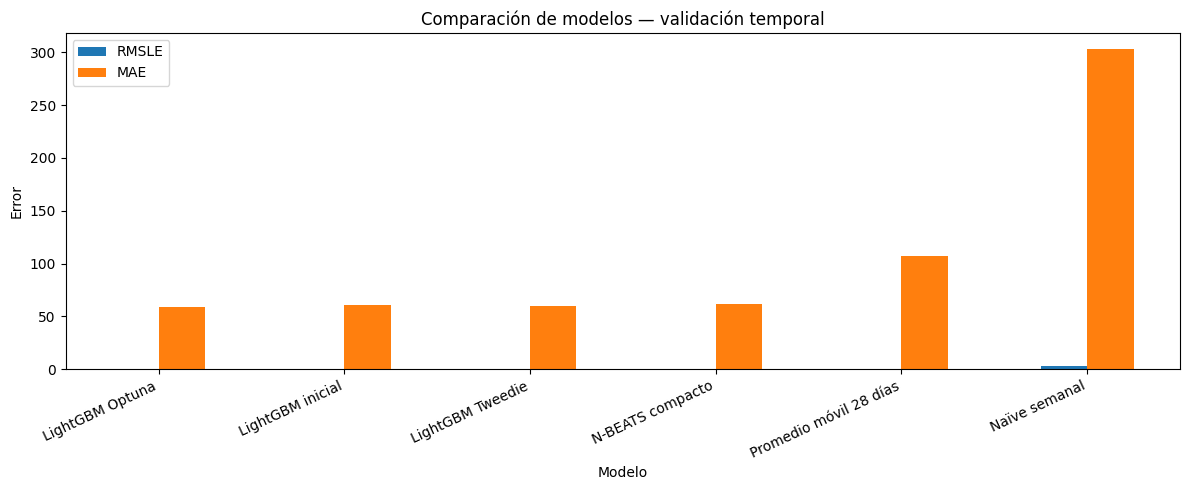

In [50]:
# Baselines calculados desde el panel histórico anterior al comienzo del bloque.
val_targets = val_df[["date", "store_nbr", "family", "target"]].copy()
hist_before_val = panel[panel["date"] < VALIDATION_START].copy()

# Predicción naïve semanal y promedio móvil, conservando exactamente
# el orden de las filas de val_targets para que las métricas sean correctas.
base_preds = {}
history_map = {
    key: grp.sort_values("date").set_index("date")["sales"]
    for key, grp in hist_before_val.groupby(series_cols, sort=False)
}
for method in ["naive_weekly", "moving_28"]:
    pred_list = []
    for row in val_targets.itertuples(index=False):
        sales_by_date = history_map.get((row.store_nbr, row.family), pd.Series(dtype=float))
        if method == "naive_weekly":
            value = sales_by_date.get(row.date - pd.Timedelta(days=7), 0.0)
        else:
            value = sales_by_date.loc[sales_by_date.index < row.date].tail(28).mean()
        pred_list.append(0.0 if pd.isna(value) else float(value))
    base_preds[method] = np.asarray(pred_list, dtype="float32")

all_results = [
    metric_row("Naïve semanal", val_targets["target"], base_preds["naive_weekly"]),
    metric_row("Promedio móvil 28 días", val_targets["target"], base_preds["moving_28"]),
    metric_row("LightGBM inicial", val_df["target"], pred_initial),
    metric_row("LightGBM Optuna", val_df["target"], pred_optimized),
    metric_row("LightGBM Tweedie", val_df["target"], pred_tweedie),
    metric_row("N-BEATS compacto", val_nn["target"], pred_nbeats)
]
final_comparison = pd.DataFrame(all_results).sort_values("RMSLE")
display(final_comparison)
final_comparison.to_csv(OUTPUT_DIR / "model_comparison_validation.csv", index=False)

ax = final_comparison.set_index("Modelo")[["RMSLE", "MAE"]].plot(kind="bar", figsize=(12,5))
ax.set_title("Comparación de modelos — validación temporal")
ax.set_ylabel("Error")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_comparison_validation.png", dpi=160)
plt.show()

## 13. Validación de origen móvil con cuatro bloques

Se conservan los cuatro periodos usados en la tercera entrega. Para cada bloque se entrena con datos anteriores al inicio del periodo y se evalúan los 16 días siguientes. La optimización de hiperparámetros se realiza únicamente con el bloque interno de validación, no con el bloque final reservado para prueba.

In [51]:
rolling_blocks = [
    (pd.Timestamp("2017-06-13"), pd.Timestamp("2017-06-28")),
    (pd.Timestamp("2017-06-29"), pd.Timestamp("2017-07-14")),
    (pd.Timestamp("2017-07-15"), pd.Timestamp("2017-07-30")),
    (pd.Timestamp("2017-07-31"), pd.Timestamp("2017-08-15"))
]

rolling_rows = []
for fold, (start, end) in enumerate(rolling_blocks, 1):
    tr = model_df[model_df["date"] < start]
    va = model_df[model_df["date"].between(start, end)]
    if tr.empty or va.empty:
        print("Bloque sin datos:", fold, start, end)
        continue
    fold_model = LGBMRegressor(
        **{**best_params, "n_estimators": max(300, int(optimized_model.best_iteration_ or 800))}
    )
    fold_model.fit(tr[feature_cols], tr["target_log"])
    p = np.maximum(np.expm1(fold_model.predict(va[feature_cols])), 0)
    row = metric_row(f"Bloque {fold}", va["target"], p)
    row.update({"Inicio": str(start.date()), "Fin": str(end.date())})
    rolling_rows.append(row)
    print(f"Bloque {fold}: RMSLE={row['RMSLE']:.4f}, MAE={row['MAE']:.3f}, WAPE={row['WAPE']:.3%}")

rolling_results = pd.DataFrame(rolling_rows)
display(rolling_results)
rolling_results.to_csv(OUTPUT_DIR / "rolling_origin_results.csv", index=False)

Bloque 1: RMSLE=0.3870, MAE=54.293, WAPE=11.896%
Bloque 2: RMSLE=0.3759, MAE=51.398, WAPE=10.602%
Bloque 3: RMSLE=0.3944, MAE=59.412, WAPE=12.332%
Bloque 4: RMSLE=0.4013, MAE=64.320, WAPE=13.769%


,Modelo,RMSLE,MAE,WAPE,Inicio,Fin
0,Bloque 1,0.387045,54.292929,0.118961,2017-06-13,2017-06-28
1,Bloque 2,0.375904,51.397717,0.106018,2017-06-29,2017-07-14
2,Bloque 3,0.394421,59.411862,0.123322,2017-07-15,2017-07-30
3,Bloque 4,0.401254,64.319617,0.137687,2017-07-31,2017-08-15


## 14. Interpretabilidad con SHAP

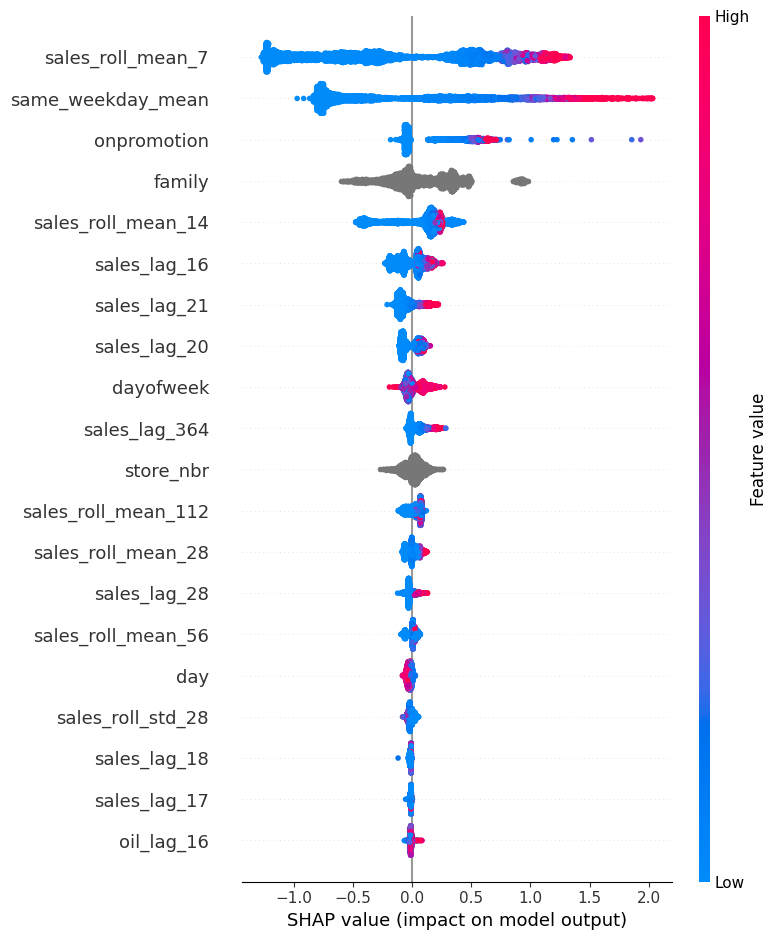

,feature,mean_abs_shap
11,sales_roll_mean_7,0.706738
17,same_weekday_mean,0.676744
23,onpromotion,0.220892
33,family,0.216317
12,sales_roll_mean_14,0.213240
0,sales_lag_16,0.099362
5,sales_lag_21,0.084051
4,sales_lag_20,0.069943
18,dayofweek,0.058090
10,sales_lag_364,0.055218


In [52]:
# Explicar una muestra para controlar el consumo de memoria.
shap_sample = val_df[feature_cols].sample(min(5000, len(val_df)), random_state=SEED)
explainer = shap.TreeExplainer(optimized_model)
shap_values = explainer.shap_values(shap_sample)
shap.summary_plot(shap_values, shap_sample, show=False, max_display=20)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "shap_summary.png", dpi=160, bbox_inches="tight")
plt.show()

importance = pd.DataFrame({
    "feature": feature_cols,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)
display(importance.head(20))
importance.to_csv(OUTPUT_DIR / "shap_feature_importance.csv", index=False)

## 15. Entrenamiento final y pronóstico de `test.csv`

El conjunto `test.csv` corresponde al periodo del 16 al 31 de agosto de 2017. Se reentrena el modelo seleccionado con todas las observaciones de entrenamiento disponibles hasta el 15 de agosto de 2017 y se genera un archivo con las columnas exigidas por Kaggle: `id` y `sales`.

La selección del modelo final se debe hacer observando las métricas obtenidas en la validación temporal. La celda utiliza LightGBM optimizado como candidato por defecto; si otro modelo obtiene un resultado mejor y estable, debe justificarse antes de cambiar la selección.

In [53]:
# Preparar features de test usando el panel que ya contiene el calendario completo.
test_features = test.copy()
# `test` ya contiene los atributos de tienda unidos en la sección de preprocesamiento.
test_features = test_features.merge(
    oil_calendar, on="date", how="left"
)
test_features["dcoilwtico"] = test_features["dcoilwtico"].ffill().bfill()

test_features = test_features.merge(
    panel[["date", "store_nbr", "family", "dayofweek", "day", "month", "dayofyear",
           "payday", "holiday_national", "holiday_regional", "holiday_local",
           "work_day_event", "special_event", "earthquake_period",
           "oil_lag_16", "transactions_lag_16"] +
          [f"sales_lag_{x}" for x in lag_days] +
          [f"sales_roll_mean_{x}" for x in [7,14,28,56,112]] +
          ["sales_roll_std_28", "same_weekday_mean"]],
    on=["date", "store_nbr", "family"], how="left"
)

# Promoción del propio día se conoce en test.
for c in cat_cols:
    if c not in test_features.columns:
        test_features = test_features.merge(stores[["store_nbr", c]].drop_duplicates(),
                                            on="store_nbr", how="left")
    test_features[c] = test_features[c].astype("category")

# Recalcular los rezagos/ventanas de las fechas test desde el panel histórico:
# se usa una unión por fecha y serie para que las features estén alineadas.
for c in feature_cols:
    if c not in test_features.columns:
        test_features[c] = np.nan
test_features["onpromotion"] = test_features["onpromotion"].fillna(0)
X_test = test_features[feature_cols].copy()

# Reentrenamiento con todo el histórico etiquetado.
final_train = model_df[model_df["date"] <= pd.Timestamp("2017-08-15")].copy()
final_model = LGBMRegressor(
    **{**best_params, "n_estimators": max(100, int(optimized_model.best_iteration_ or 800))}
)
final_model.fit(final_train[feature_cols], final_train["target_log"])

test_pred = np.maximum(np.expm1(final_model.predict(X_test)), 0)
# Regla de serie inactiva: cero si no hubo ventas en los 56 días anteriores al corte.
recent_final = panel[
    (panel["date"] >= pd.Timestamp("2017-06-20")) &
    (panel["date"] <= pd.Timestamp("2017-08-15"))
].groupby(series_cols, observed=True)["sales"].sum()
inactive_final = set(recent_final[recent_final == 0].index.tolist())
inactive_test_mask = np.array([
    (row.store_nbr, row.family) in inactive_final
    for row in test[["store_nbr", "family"]].itertuples(index=False)
])
test_pred[inactive_test_mask] = 0
submission = pd.DataFrame({"id": test["id"], "sales": test_pred})
submission.to_csv(OUTPUT_DIR / "submission.csv", index=False)
print("Archivo generado:", OUTPUT_DIR / "submission.csv")
display(submission.head())
assert list(submission.columns) == ["id", "sales"]
assert len(submission) == len(test)

Archivo generado: /content/favorita_project/outputs/submission.csv


,id,sales
0,3000888,1.087629
1,3000889,0.000000
2,3000890,9.503981
3,3000891,2128.143315
4,3000892,0.106356


## 16. Guardar modelos, resultados y archivos para Streamlit

In [54]:
import joblib

joblib.dump(final_model, MODEL_DIR / "lightgbm_final.joblib")
joblib.dump(optimized_model, MODEL_DIR / "lightgbm_optimized.joblib")
joblib.dump(tweedie_model, MODEL_DIR / "lightgbm_tweedie.joblib")
torch.save(nn_model.state_dict(), MODEL_DIR / "nbeats_compact.pt")

# Exportar predicciones de validación para el tablero y el análisis.
val_export = val_df[["date", "store_nbr", "family", "target"]].copy()
val_export["pred_lightgbm"] = pred_optimized
val_export["pred_tweedie"] = pred_tweedie
val_export.to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)

# Resumen reproducible de configuración y resultados.
run_info = {
    "seed": SEED,
    "horizon_days": HORIZON,
    "features": feature_cols,
    "best_optuna_params": best_params,
    "lightgbm_best_iteration": int(optimized_model.best_iteration_ or 0),
    "validation_metrics": final_comparison.to_dict(orient="records"),
    "rolling_origin": rolling_results.to_dict(orient="records") if len(rolling_results) else []
}
with open(OUTPUT_DIR / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(run_info, f, ensure_ascii=False, indent=2, default=str)

# Crear paquete descargable con artefactos (no incluye el dataset original).
artifact_zip = BASE_DIR / "entrega_colab_artifacts.zip"
with zipfile.ZipFile(artifact_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [OUTPUT_DIR, MODEL_DIR]:
        for file in folder.rglob("*"):
            if file.is_file():
                z.write(file, file.relative_to(BASE_DIR))
print("Artefactos guardados:", artifact_zip)

Artefactos guardados: /content/favorita_project/entrega_colab_artifacts.zip


In [59]:
import pandas as pd
import numpy as np

submission = pd.read_csv(
    "/content/favorita_project/outputs/submission.csv"
)

print("Filas:", len(submission))
print("Columnas:", submission.columns.tolist())
print("Valores nulos:", submission.isnull().sum().to_dict())
print("Valores negativos:", (submission["sales"] < 0).sum())
print("Valores infinitos:", np.isinf(submission["sales"]).sum())
print("\nResumen de predicciones:")
print(submission["sales"].describe())

Filas: 28512
Columnas: ['id', 'sales']
Valores nulos: {'id': 0, 'sales': 0}
Valores negativos: 0
Valores infinitos: 0

Resumen de predicciones:
count    28512.000000
mean       300.872049
std        718.193036
min          0.000000
25%          0.362494
50%          2.904596
75%        197.700453
max       7470.685893
Name: sales, dtype: float64


In [60]:
print("Última fecha del panel:", panel["date"].max())
print("Filas de test:", len(test))
print("Filas de test_features:", len(test_features))
print("Filas de X_test:", len(X_test))

print("\nPorcentaje de valores vacíos por característica:")
display(
    (X_test.isna().mean() * 100)
    .sort_values(ascending=False)
    .to_frame("Porcentaje vacío")
)

Última fecha del panel: 2017-08-15 00:00:00
Filas de test: 28512
Filas de test_features: 28512
Filas de X_test: 28512

Porcentaje de valores vacíos por característica:


,Porcentaje vacío
sales_lag_16,100.0
sales_lag_17,100.0
sales_lag_18,100.0
sales_lag_19,100.0
sales_lag_20,100.0
sales_lag_21,100.0
sales_lag_28,100.0
sales_lag_35,100.0
sales_lag_42,100.0
sales_lag_49,100.0


In [61]:
# ============================================================
# CORRECCIÓN DE FEATURES DE TEST SIN REENTRENAR EL MODELO
# ============================================================

import numpy as np
import pandas as pd

# Comprobar que el modelo entrenado sigue en memoria.
if "final_model" not in globals():
    raise RuntimeError(
        "No encuentro final_model en memoria. No entrenes otro modelo; "
        "avísame antes de continuar."
    )

HORIZON = 16
series_cols = ["store_nbr", "family"]

# Histórico disponible hasta el 15 de agosto.
hist = (
    panel[["date", "store_nbr", "family", "sales"]]
    .copy()
    .sort_values(["store_nbr", "family", "date"])
)

hist["date"] = pd.to_datetime(hist["date"])

# Fechas de referencia para consultar el histórico.
test_features = test.copy()
test_features["date"] = pd.to_datetime(test_features["date"])
test_features["feature_date"] = (
    test_features["date"] - pd.Timedelta(days=HORIZON)
)

# ------------------------------------------------------------
# 1. Rezagos de ventas
# ------------------------------------------------------------

for lag in [16, 17, 18, 19, 20, 21, 28, 35, 42, 49, 364]:

    lookup = hist[["date", "store_nbr", "family", "sales"]].copy()
    lookup["feature_date"] = lookup["date"] + pd.Timedelta(days=lag)
    lookup = lookup.drop(columns="date")
    lookup = lookup.rename(columns={"sales": f"sales_lag_{lag}"})

    test_features = test_features.merge(
        lookup,
        on=["feature_date", "store_nbr", "family"],
        how="left"
    )

# ------------------------------------------------------------
# 2. Promedios móviles y desviación estándar
# ------------------------------------------------------------

grouped_sales = hist.groupby(
    series_cols, sort=False, observed=True
)["sales"]

for window in [7, 14, 28, 56, 112]:

    rolling_mean = grouped_sales.transform(
        lambda s: s.rolling(window, min_periods=1).mean()
    )

    temp = hist[["date", "store_nbr", "family"]].copy()
    temp[f"sales_roll_mean_{window}"] = rolling_mean

    temp = temp.rename(columns={"date": "feature_date"})

    test_features = test_features.merge(
        temp,
        on=["feature_date", "store_nbr", "family"],
        how="left"
    )

rolling_std = grouped_sales.transform(
    lambda s: s.rolling(28, min_periods=2).std()
).fillna(0)

temp = hist[["date", "store_nbr", "family"]].copy()
temp["sales_roll_std_28"] = rolling_std
temp = temp.rename(columns={"date": "feature_date"})

test_features = test_features.merge(
    temp,
    on=["feature_date", "store_nbr", "family"],
    how="left"
)

# ------------------------------------------------------------
# 3. Promedio del mismo día de la semana
# ------------------------------------------------------------

same_weekday = []

for lag in [21, 28, 35, 42, 49, 56]:
    col = f"sales_lag_{lag}"
    same_weekday.append(test_features[col])

test_features["same_weekday_mean"] = pd.concat(
    same_weekday, axis=1
).mean(axis=1)

# ------------------------------------------------------------
# 4. Variables del calendario
# ------------------------------------------------------------

test_features["dayofweek"] = test_features["date"].dt.dayofweek
test_features["day"] = test_features["date"].dt.day
test_features["month"] = test_features["date"].dt.month
test_features["dayofyear"] = test_features["date"].dt.dayofyear

test_features["payday"] = (
    test_features["date"].dt.day.isin([15, 16]) |
    test_features["date"].dt.is_month_end
).astype("int8")

test_features["holiday_national"] = (
    test_features["date"].isin(hol_national_dates)
).astype("int8")

test_features["holiday_regional"] = (
    test_features[["date", "state"]].merge(
        regional,
        left_on=["date", "state"],
        right_on=["date", "locale_name"],
        how="left"
    )["locale_name"].notna().to_numpy().astype("int8")
)

test_features["holiday_local"] = (
    test_features[["date", "city"]].merge(
        local,
        left_on=["date", "city"],
        right_on=["date", "locale_name"],
        how="left"
    )["locale_name"].notna().to_numpy().astype("int8")
)

test_features["work_day_event"] = (
    test_features["date"].isin(work_dates)
).astype("int8")

test_features["special_event"] = (
    test_features["date"].isin(event_dates)
).astype("int8")

test_features["earthquake_period"] = (
    (test_features["date"] >= pd.Timestamp("2016-04-16")) &
    (test_features["date"] <= pd.Timestamp("2016-05-16"))
).astype("int8")

# ------------------------------------------------------------
# 5. Variables externas con rezago de 16 días
# ------------------------------------------------------------

oil_lookup = oil_calendar[["date", "dcoilwtico"]].copy()
oil_lookup["date"] = pd.to_datetime(oil_lookup["date"])
oil_lookup = oil_lookup.rename(columns={
    "date": "feature_date",
    "dcoilwtico": "oil_lag_16"
})

test_features = test_features.merge(
    oil_lookup,
    on="feature_date",
    how="left"
)

transactions_lookup = transactions_calendar[
    ["date", "store_nbr", "transactions_value"]
].copy()

transactions_lookup["date"] = pd.to_datetime(
    transactions_lookup["date"]
)

transactions_lookup = transactions_lookup.rename(columns={
    "date": "feature_date",
    "transactions_value": "transactions_lag_16"
})

test_features = test_features.merge(
    transactions_lookup,
    on=["feature_date", "store_nbr"],
    how="left"
)

# ------------------------------------------------------------
# 6. Preparar las variables categóricas
# ------------------------------------------------------------

cat_cols = ["store_nbr", "family", "city", "type", "cluster"]

for c in cat_cols:
    test_features[c] = pd.Categorical(
        test_features[c],
        categories=panel[c].cat.categories
    )

# Promoción conocida en el conjunto de prueba.
test_features["onpromotion"] = (
    test_features["onpromotion"].fillna(0)
)

# ------------------------------------------------------------
# 7. Construir X_test en el orden original
# ------------------------------------------------------------

X_test = test_features[feature_cols].copy()

print("Dimensiones de X_test:", X_test.shape)

print("\nPorcentaje de valores vacíos:")
display(
    (X_test.isna().mean() * 100)
    .sort_values(ascending=False)
    .to_frame("Porcentaje vacío")
)

# No continuar si todavía hay características numéricas vacías.
numeric_cols = X_test.select_dtypes(
    include=["number"]
).columns

if X_test[numeric_cols].isna().any().any():
    raise ValueError(
        "Todavía hay valores vacíos en variables numéricas. "
        "Revisa la tabla antes de generar la entrega."
    )

# ------------------------------------------------------------
# 8. Predecir con el modelo YA ENTRENADO
# ------------------------------------------------------------

test_pred = np.maximum(
    np.expm1(final_model.predict(X_test)),
    0
)

# Mantener la regla de series inactivas del proyecto.
recent_final = panel[
    (panel["date"] >= pd.Timestamp("2017-06-20")) &
    (panel["date"] <= pd.Timestamp("2017-08-15"))
].groupby(series_cols, observed=True)["sales"].sum()

inactive_final = set(
    recent_final[recent_final == 0].index.tolist()
)

inactive_test_mask = np.array([
    (row.store_nbr, row.family) in inactive_final
    for row in test[["store_nbr", "family"]].itertuples(index=False)
])

test_pred[inactive_test_mask] = 0

# Crear y guardar el archivo final.
submission = pd.DataFrame({
    "id": test["id"],
    "sales": test_pred
})

submission.to_csv(
    OUTPUT_DIR / "submission.csv",
    index=False
)

print("\n¡Corrección terminada!")
print("Archivo:", OUTPUT_DIR / "submission.csv")
print("Filas:", len(submission))
print("Valores vacíos:", submission.isna().sum().sum())
print("Predicciones negativas:", (submission["sales"] < 0).sum())

display(submission.head())

KeyError: 'sales_lag_56'

## 17. Descarga de resultados

Al finalizar correctamente todas las secciones, se puede descargar el ZIP con modelos, predicciones, métricas, gráficas y configuración.

In [62]:
from google.colab import files
files.download(str(artifact_zip))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [56]:
from pathlib import Path

print("CARPETA DE RESULTADOS:")
print(OUTPUT_DIR)

print("\nARCHIVOS GENERADOS:")
for archivo in sorted(Path(OUTPUT_DIR).glob("*")):
    print(archivo.name, "-", round(archivo.stat().st_size / 1024, 2), "KB")

CARPETA DE RESULTADOS:
/content/favorita_project/outputs

ARCHIVOS GENERADOS:
comparison_lightgbm.csv - 0.24 KB
model_comparison_validation.csv - 0.46 KB
model_comparison_validation.png - 75.61 KB
optuna_trials.csv - 7.1 KB
rolling_origin_results.csv - 0.38 KB
run_summary.json - 2.95 KB
shap_feature_importance.csv - 1.24 KB
shap_summary.png - 190.25 KB
submission.csv - 708.67 KB
validation_predictions.csv - 1854.48 KB


In [58]:
print("¿Existe panel?:", "panel" in globals())
print("¿Existe model_df?:", "model_df" in globals())
print("¿Existe train_df?:", "train_df" in globals())
print("¿Existe optimized_model?:", "optimized_model" in globals())
print("¿Existe tweedie_model?:", "tweedie_model" in globals())

¿Existe panel?: True
¿Existe model_df?: True
¿Existe train_df?: True
¿Existe optimized_model?: True
¿Existe tweedie_model?: True


## 18. Controles antes de redactar el artículo definitivo

No redactar los resultados finales hasta comprobar:

- [ ] Se cargaron los seis CSV originales correctos.
- [ ] Se generaron las 37 características documentadas.
- [ ] La división temporal no utiliza información futura.
- [ ] Optuna terminó y se guardó `optuna_trials.csv`.
- [ ] Tweedie fue evaluado con la misma ventana temporal.
- [ ] La red neuronal terminó entrenamiento y fue evaluada en el mismo bloque.
- [ ] Se generó la tabla comparativa de RMSLE, MAE y WAPE.
- [ ] Se ejecutó la validación de origen móvil.
- [ ] SHAP generó el gráfico y la importancia de variables.
- [ ] `submission.csv` tiene las columnas `id` y `sales` y 28.512 filas.
- [ ] Los modelos y artefactos se guardaron correctamente.

**Nota metodológica:** esta versión reconstruye el flujo a partir de lo que está descrito en la tercera entrega. La ejecución real puede revelar ajustes necesarios, especialmente en el tratamiento de feriados trasladados, series sin ventas, alineación de características de test y recursos disponibles en Colab. Cualquier cambio debe quedar registrado y reflejarse después en el artículo.